In [ ]:
import pandas as pd
import os

BASE_DIR = os.getcwd()
df = pd.read_csv(os.path.join(BASE_DIR, 'online_retail.csv'), encoding='ISO-8859-1')

print("Original shape:", df.shape)

Original shape: (541909, 8)


In [ ]:
df = df.dropna(subset=['CustomerID'])
print("After dropping missing CustomerID:", df.shape)

After dropping missing CustomerID: (406829, 8)


In [ ]:
before = df.shape[0]
df = df.drop_duplicates()
print(f"Removed {before - df.shape[0]} duplicate rows")

Removed 5225 duplicate rows


In [ ]:
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
cancelled = df[df['InvoiceNo'].str.startswith('C')]
df = df[~df['InvoiceNo'].str.startswith('C')]
print(f"Separated {cancelled.shape[0]} cancelled order rows")

Separated 8872 cancelled order rows


In [ ]:
before = df.shape[0]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
print(f"Removed {before - df.shape[0]} rows with invalid quantity/price")

Removed 40 rows with invalid quantity/price


In [ ]:
df['Description'] = df['Description'].str.strip().str.upper()

In [ ]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [ ]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']

In [ ]:
print("\nFinal shape:", df.shape)
print(df.isnull().sum())
print(df.head())

df.to_csv(os.path.join(BASE_DIR, 'cleaned_online_retail.csv'), index=False)


Final shape: (392692, 9)
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
4 2010-12-01 08

In [ ]:
# Group revenue by month and calculate total revenue for each month
df['Month'] = df['InvoiceDate'].dt.to_period('M')
monthly_revenue = df.groupby('Month')['Revenue'].sum().reset_index()

print(monthly_revenue)

      Month      Revenue
0   2010-12   570422.730
1   2011-01   568101.310
2   2011-02   446084.920
3   2011-03   594081.760
4   2011-04   468374.331
5   2011-05   677355.150
6   2011-06   660046.050
7   2011-07   598962.901
8   2011-08   644051.040
9   2011-09   950690.202
10  2011-10  1035642.450
11  2011-11  1156205.610
12  2011-12   517190.440


In [ ]:
# Group by product and calculate total revenue for each product
top_products = df.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
MANUAL                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Revenue, dtype: float64


In [ ]:
# Group by customer and calculate total revenue for each customer
top_customers = df.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False).head(10)

print(top_customers)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64


In [ ]:
# Group revenue by country and calculate total revenue for each country
country_revenue = df.groupby('Country')['Revenue'].sum().reset_index()

print(country_revenue)

                 Country      Revenue
0              Australia   138453.810
1                Austria    10198.680
2                Bahrain      548.400
3                Belgium    41196.340
4                 Brazil     1143.600
5                 Canada     3666.380
6        Channel Islands    20440.540
7                 Cyprus    13502.850
8         Czech Republic      826.740
9                Denmark    18955.340
10                  EIRE   265262.460
11    European Community     1300.250
12               Finland    22546.080
13                France   208934.310
14               Germany   228678.400
15                Greece     4760.520
16               Iceland     4310.000
17                Israel     7215.840
18                 Italy    17483.240
19                 Japan    37416.370
20               Lebanon     1693.880
21             Lithuania     1661.060
22                 Malta     2725.590
23           Netherlands   285446.340
24                Norway    36165.440
25          

In [ ]:
# Calculate the average order value
average_order_value = df['Revenue'].mean()

print(f"Average Order Value: {average_order_value}")

Average Order Value: 22.631499735161402


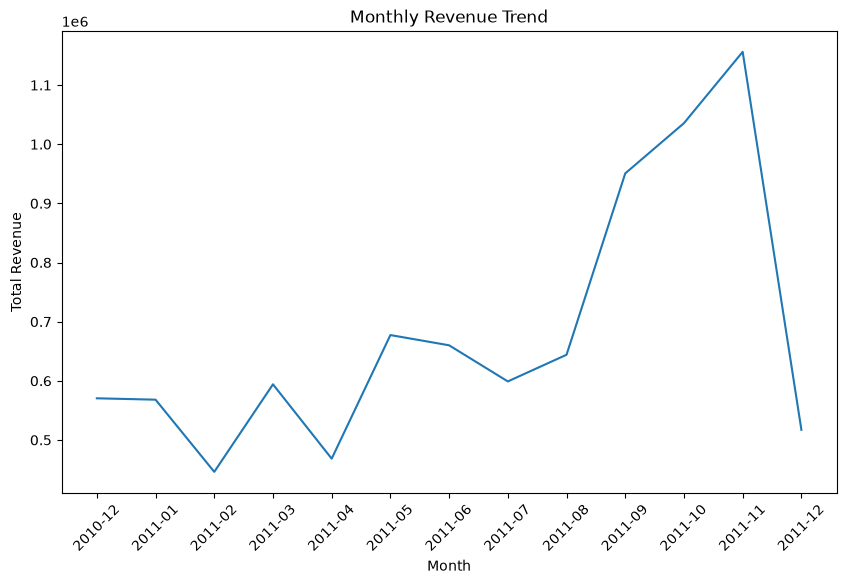

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Group revenue by month and calculate total revenue for each month
df['Month'] = df['InvoiceDate'].dt.to_period('M')
monthly_revenue = df.groupby('Month')['Revenue'].sum().reset_index()

# Convert Month to string with format 'YYYY-MM'
monthly_revenue['Month'] = monthly_revenue['Month'].astype(str).str.replace(r'(\d{4})-(\d{1,2})', r'\1-\2')

# Create a line chart for monthly revenue
plt.figure(figsize=(10, 6))
sns.lineplot(x='Month', y='Revenue', data=monthly_revenue)
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)  # Rotate x-axis labels for better readability
plt.show()

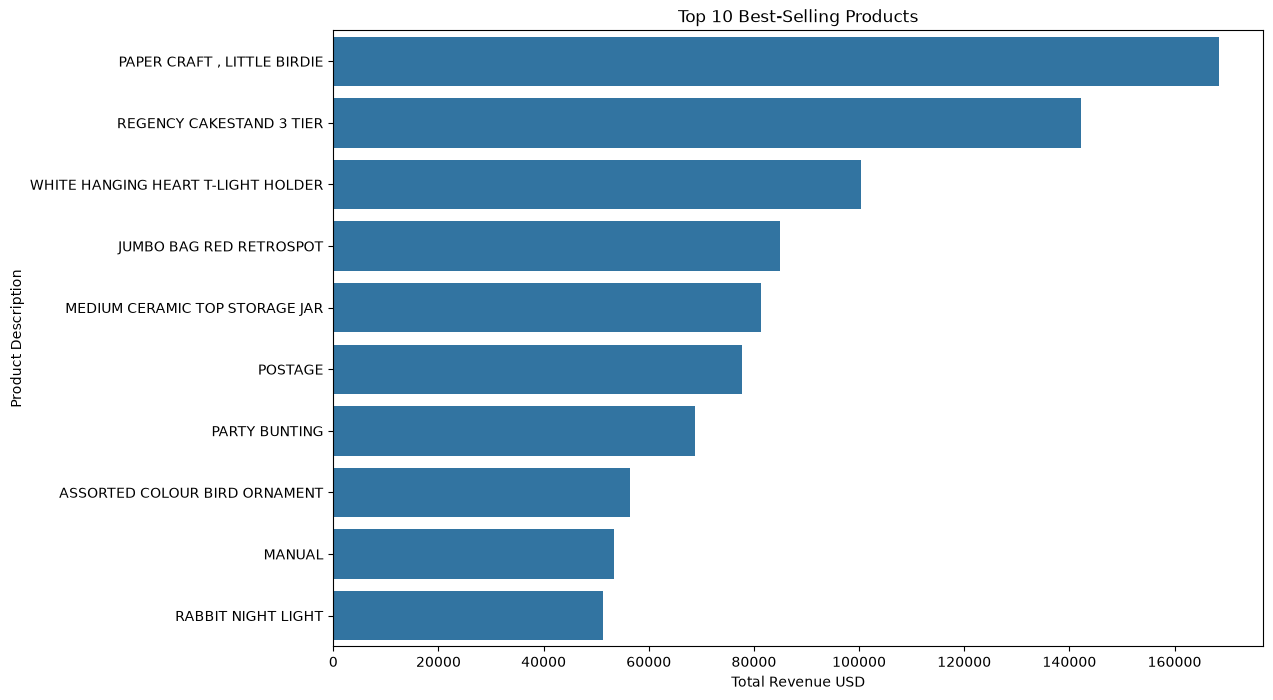

In [ ]:
# Group by product and calculate total revenue for each product
top_products = df.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)

# Create a horizontal bar chart for top 10 best-selling products
plt.figure(figsize=(12, 8))
sns.barplot(x='Revenue', y='Description', data=top_products.reset_index(), orient='h')
plt.title('Top 10 Best-Selling Products')
plt.xlabel('Total Revenue USD')
plt.ylabel('Product Description')
plt.show()

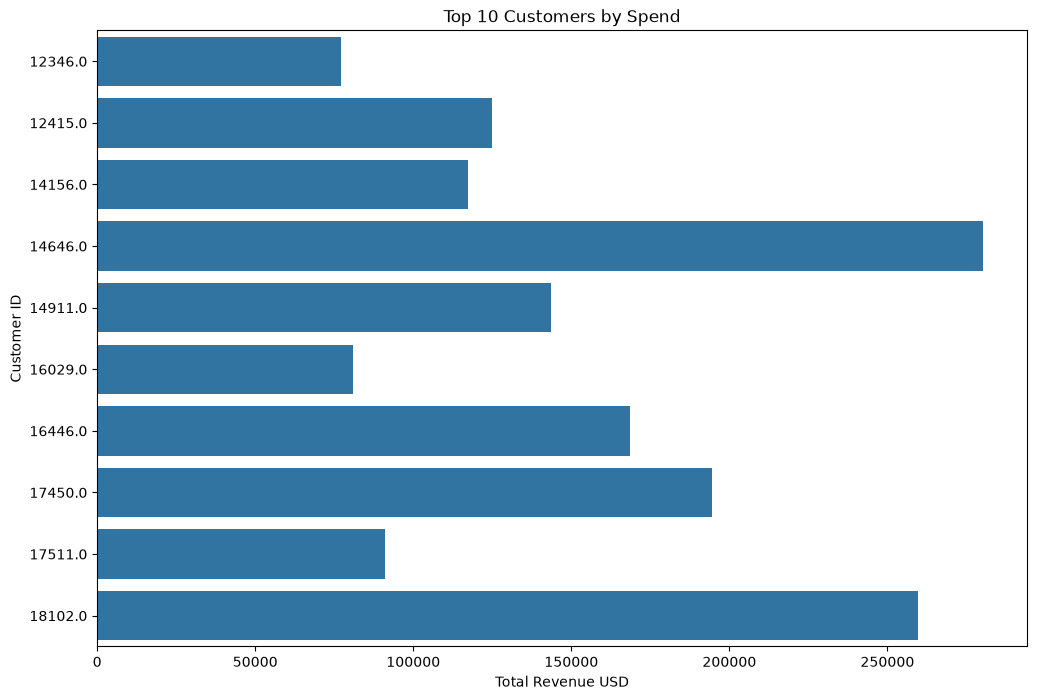

In [ ]:
# Group by customer and calculate total revenue for each customer
top_customers = df.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False).head(10)

# Create a horizontal bar chart for top 10 customers by spend
plt.figure(figsize=(12, 8))
sns.barplot(x='Revenue', y='CustomerID', data=top_customers.reset_index(), orient='h')
plt.title('Top 10 Customers by Spend')
plt.xlabel('Total Revenue USD')
plt.ylabel('Customer ID')
plt.show()

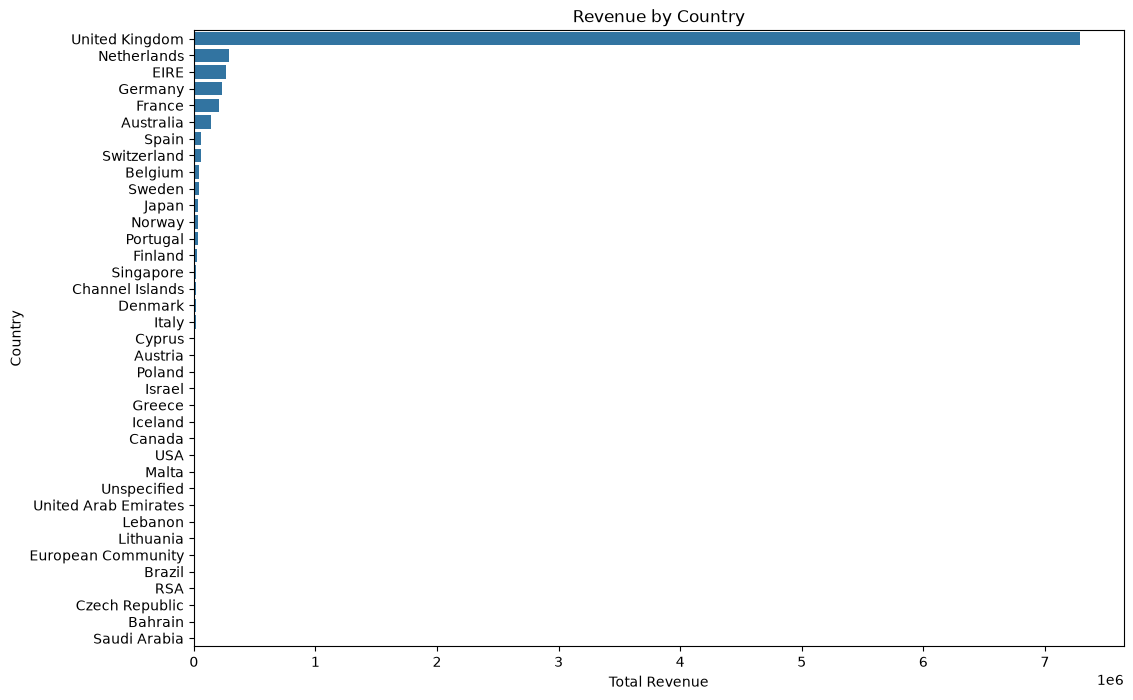

In [ ]:
# Group revenue by country and calculate total revenue for each country
country_revenue = df.groupby('Country')['Revenue'].sum().reset_index()

# Create a bar chart for revenue by country
plt.figure(figsize=(12, 8))
sns.barplot(x='Revenue', y='Country', data=country_revenue.sort_values(by='Revenue', ascending=False).reset_index(), orient='h')
plt.title('Revenue by Country')
plt.xlabel('Total Revenue')
plt.ylabel('Country')
plt.show()

In [ ]:
# Function to parse dates
def parse_date(date_str):
    if '/' in date_str:
        return pd.to_datetime(date_str, format='%d/%m/%Y %H:%M')
    elif '-' in date_str:
        return pd.to_datetime(date_str, format='%Y-%m-%d %H:%M:%S')
    else:
        raise ValueError(f"Unrecognized date format: {date_str}")

# Get the current working directory
BASE_DIR = os.getcwd()

# Read the CSV file
df = pd.read_csv(os.path.join(BASE_DIR, 'online_retail.csv'), encoding='ISO-8859-1')

# Drop rows with missing CustomerID
df.dropna(subset=['CustomerID'], inplace=True)

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Handle negative Quantity and UnitPrice (assuming these are cancelled orders)
df = df[(df['Quantity'] >= 0) & (df['UnitPrice'] >= 0)]

# Standardize text columns: strip whitespace, fix casing in Description
df['Description'] = df['Description'].str.strip().str.lower()

# Convert InvoiceDate to proper datetime using a custom function
df['InvoiceDate'] = df['InvoiceDate'].apply(parse_date)

# Create a calculated Revenue column
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# Save the cleaned DataFrame to a new CSV file
cleaned_file_path = os.path.join(BASE_DIR, 'online_retail_cleaned.csv')
df.to_csv(cleaned_file_path, index=False)
print(f"Cleaned data saved to: {cleaned_file_path}")

# Read the cleaned data back into a DataFrame using the absolute path
abs_cleaned_file_path = os.path.abspath(cleaned_file_path)
cleaned_df = pd.read_csv(abs_cleaned_file_path)

# Display the first few rows of the DataFrame
print(cleaned_df.head())

# Get summary information about the DataFrame
print(cleaned_df.info())

# Get basic statistics for numerical columns
print(cleaned_df.describe())

Cleaned data saved to: c:\Users\LEGION\Documents\portfolio-projects\01-sales-dashboard\online_retail_cleaned.csv
   InvoiceNo StockCode                          Description  Quantity  \
0     536365    85123A   white hanging heart t-light holder         6   
1     536365     71053                  white metal lantern         6   
2     536365    84406B       cream cupid hearts coat hanger         8   
3     536365    84029G  knitted union flag hot water bottle         6   
4     536365    84029E       red woolly hottie white heart.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
<class 'pa